In [15]:
# lo so è pieno di roba inutile

import numpy as np
import pandas as pd
from itertools import cycle
from matplotlib.path import Path as MplPath
import tifffile as tiff
import sys
from pathlib import Path
import plotly.graph_objects as go
from phasorpy.plot import PhasorPlot     # phasor plot stolen from phasorpy 

# personal stuff
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost

import lib.randgen
import lib.my_stats


# 1. Exponential data generation

In [16]:
τ_true = 3 # ns
N_evt = 10000
T_laser = 12.5  #ns

tempi = np.random.exponential(scale = τ_true, size = N_evt)
n, xe = np.histogram(tempi, bins = 'auto')   
    # xe = bin edges, n = bin heights


<h3> Binned NNL fit (only made for comparison purposes)

In [17]:
def expon_cdf(x, A, τ):
    return A * τ * (1.0 - np.exp(-x / τ))   # I need cdf for the binned likelihood 


#fixing crazy chi squared results
A_guess, tau_guess = n[0], np.mean(tempi)

c_binned = cost.ExtendedBinnedNLL(n, xe, expon_cdf)
m = Minuit(c_binned, A = A_guess, τ = tau_guess)
m.limits["τ"], m.limits["A"] = (0.001, None), (0.001, None)     # placing lower limits on both parameters to avoid negative values
m.migrad()

print("Params")
# if i dont leave an empty line, params will not display for some reason
display(m.params)

print("\nStats")
lib.my_stats.minuit_stats(m)


Params


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,A,3.36e3,0.05e3,,,0.001,,
1,τ,2.982,0.030,,,0.001,,



Stats
chi-squared: 112.79
reduced chi-squared: 1.38
dof: 82.00
p-value: 0.01


# 2. Phasor plot and noise addition

Functions for calculating and plotting phasors (given a histogram)

In [18]:
def phasor_calc (n, harm_n = 1):   # given a histogram n (xe), calculates the phasor coordinates G and S

    fft_vals = np.fft.fft(n)
    fft_norm = fft_vals / fft_vals[0]
    
    G, S = np.real(fft_norm[harm_n]), -np.imag(fft_norm[harm_n])

    return G, S


#######################################################################################################



def data_and_phasor_plot(xe, n, G, S, T_laser):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

    # hist + plot
    bin_centers = 0.5 * (xe[:-1] + xe[1:])    # select bin centers

    ax1.hist(tempi, bins = xe, density = False, alpha = 0.3, color = 'steelblue', edgecolor = 'midnightblue', label = 'Data')

    ax1.plot(bin_centers, n, color = 'crimson', marker = '', linestyle = '-', linewidth = 1.5)

    ax1.set_xlabel('t (ns)', fontsize = 12)
    ax1.set_ylabel('counts', fontsize = 12)
    # ax1.legend(fontsize = 11, frameon = True, shadow = True)
    ax1.grid(alpha = 0.3)
    ax1.set_xlim(0, xe[-1])

    # phasor plane
    ω_laser = 1000.0 / T_laser  # Calcolo della frequenza in MHz
    plot = PhasorPlot(frequency = ω_laser, ax = ax2)

    plot.plot([G], [S], marker = 'x', markersize = 10, markeredgewidth = 2, 
              color = 'crimson', label = 'Fasore (Dati)')

    #ax2.legend(loc='upper right', fontsize=11, frameon=True, shadow=True)

    plt.tight_layout()
    plt.show()



###################################################################################################



def add_noise(counts, snr_db):  # Adds GAUSSIAN NOISE (why not Poisson? Need to check if it is correct)

    rng = np.random.default_rng()   
    snr_linear = 10 ** (snr_db / 10)  # convert SNR from dB to linear scale 

    sig_power = np.mean(counts ** 2, axis = 0) 
    noise_std = np.sqrt(sig_power / snr_linear)
    noise = rng.standard_normal(counts.shape) * noise_std
    
    return np.clip(counts + noise, 0, None)


Testing phasor, plotting, and noise functions

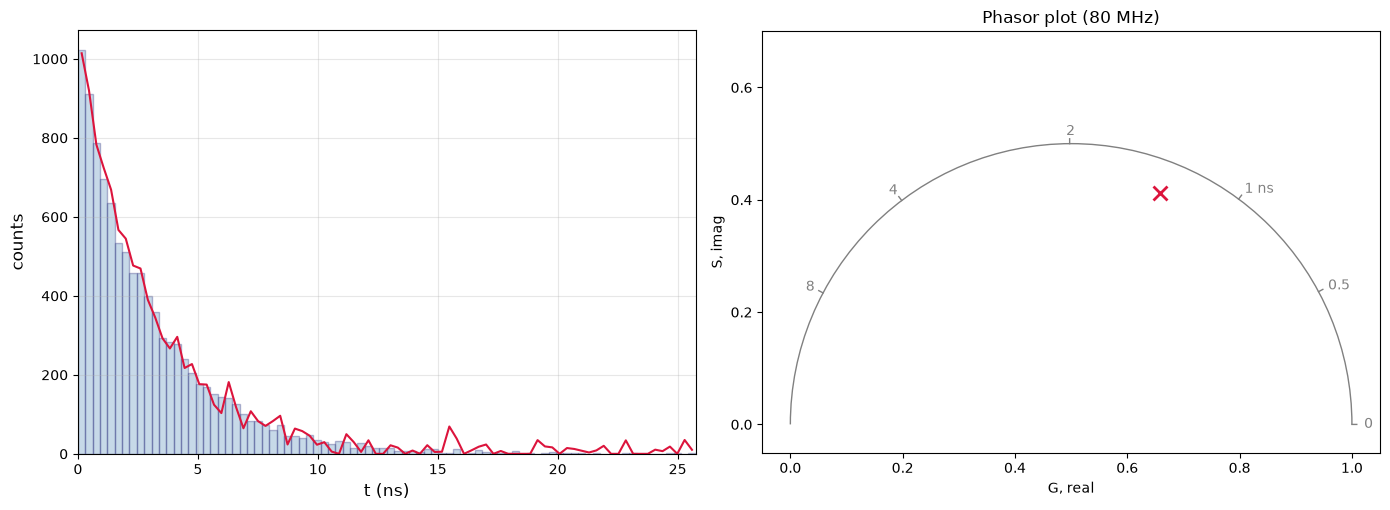

In [19]:
noise_bool = True     # toggle to add noise
if noise_bool: n = add_noise(n, snr_db = 20)   # higher snr = less noise

#phasors = [phasor_calc(n, harm_n) for harm_n in range(1, 4)]  # calculate phasors for the first three harmonics
#data_and_phasor_plot(xe, n, phasors[0][0], phasors[0][1], T_laser=12.5)  # [0][1] = first harmonic, S

phasors = phasor_calc(n)   # commented the version that displays multiple harmonics
data_and_phasor_plot(xe, n, phasors[0], phasors[1], T_laser)


# 3. Simulation of data + IRF convolution

2 parole su cosa devo fare per vedere se ho capito. Spegazione presa dal file mmc5.pdf

IRF = Instrument Response Function, è la funzione di risposta al laser data dal rivelatore. È fondamentalmente il profilo temporale della risposta del sistema di rilevamento a un impulso laser brevissimo.

Il sistema di rilevamento infatti presenta sempre un errore nella risposta intrinseco dovuto a motivi fisici/elettronici (e quindi non riproducibile).
Studiare l'IRF permette di ottenere informazioni su questo errore e dunque correggere anche i dati di FLIM raccolti.

Nella pratica:
    decadimento rilevato = convoluzione(decadimento reale, IRF)

In [20]:
def irf_generation(σ, μ, counts, T_laser, num_bins=4096):       # I'm generating a gaussian IRF

    time_bins = np.linspace(0, T_laser, num_bins)
    
    irf = np.exp(-((time_bins - μ)**2) / (2 * σ**2))
    
    irf /= np.sum(irf)
    irf *= counts
    
    return time_bins, irf



#############################################################################################################



def simulation_with_IRF(tempi1, irf, counts, noise_flag, snr_db):

    n_bins = len(irf)
    
    convol = np.convolve(tempi1, irf, mode = 'full')[:n_bins]       # copy pasted, need to check what is going on here    
    
    convol = (convol / np.sum(convol)) * counts  # Normalization
    
    #NOISEEEEE
    if noise_flag: noisy_signal = add_noise(convol, snr_db) 
    else: noisy_signal = convol
    
    return convol, noisy_signal




##############################################################################################################


def phasor_deconv(G_meas, S_meas, G_irf, S_irf):
 
    z_meas = G_meas + 1j * S_meas  # imaginary unit i = 1j
    z_irf = G_irf + 1j * S_irf
    
    z_deconvol = z_meas / z_irf       # in phasor plane, convolution = moltiplication
    
    G_deconvol, S_deconvol = np.real(z_deconvol), np.imag(z_deconvol)
    
    return G_deconvol, S_deconvol


In [27]:
T_laser = 12.5
N_evt1 = 10000       

μ, σ = 1.0, 0.1

tempi1_val = np.random.exponential(scale = τ_true, size = N_evt)
time_bins = np.linspace(0, T_laser, 4096)
n1, xe1= np.histogram(tempi1_val, bins = time_bins)   

noise_bool1, snr_db1 = True, 20  

time_bins, irf = irf_generation(σ, μ, N_evt1, T_laser, len(n1))

convoluted_signal, noisy_signal = simulation_with_IRF(n1, irf, N_evt1, noise_bool1, snr_db1)


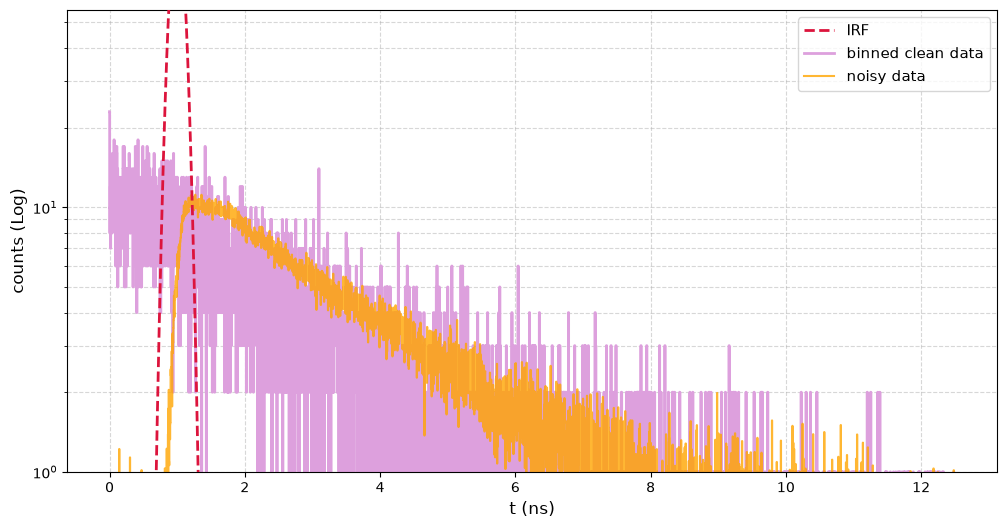

In [30]:
plt.figure(figsize=(12, 6))

signal_max = np.max(noisy_signal)
irf_plot = irf

plt.plot(time_bins, irf_plot, label = 'IRF', color = 'crimson', linestyle = '--', zorder = 3, linewidth = 2)
  
plt.step(xe1[:-1], n1, where = 'mid', label = 'binned clean data', color = 'plum', linewidth = 2)

plt.step(time_bins, noisy_signal, where = 'mid', label = 'noisy data', color = 'orange', alpha = 0.8)

plt.yscale('log')

plt.ylim(bottom = 1, top = signal_max * 5) 

plt.xlabel('t (ns)', fontsize = 12)  
plt.ylabel('counts (Log)', fontsize = 12)
plt.grid(True, which = "both", linestyle = "--", alpha = 0.5)
plt.legend(loc = 'upper right', fontsize = 11)

plt.show()

# 4. Working on an imported image

<h3> Functions for this section

In [ ]:
def image_flattener(image):     # shows a 2d image with the amount of photons per pixel in total time
    flat_image = np.sum(image, axis =0)     # sum of total photons

    plt.imshow(flat_image, cmap = 'magma') # alternatives: plasma, viridis, gray
    plt.colorbar(label = 'total counts')

    # auto select point with highest counts
    max_index = np.unravel_index(np.argmax(flat_image), flat_image.shape)

    plt.scatter(max_index[1], max_index[0], facecolors = 'none', edgecolors = 'cyan', marker = 'o', 
                s = 100, linewidths = 2, label = f'x = {max_index[1]}, y = {max_index[0]}')

    plt.legend()
    plt.show()



############################################################################################################


def pixel_exponential(image):

    # 4096 bins spalmati su 12.5 ns. 
    x = np.linspace(0, 12.5, image.shape[0])

    plt.figure(figsize=(17, 5))

    plt.step(x, image[:, 12, 103], where = 'mid', color = 'plum', linewidth = 1.5)

    plt.yscale('log')   # I am using log scale on y because it's what every single paper I found on the internet did

    # 12.5 ns / 4096 bins = 0.00305 ns per bin
    plt.xlabel('time (ns)', fontsize=12)  
    plt.ylabel('counts (Log)', fontsize=12)
    plt.grid(True, which="major", linestyle="-", alpha=0.5)

    plt.show()



############################################################################################################



def extract_IRF(image, xe, T_laser):        # this only works if I have an isolated image/tiff of a IRF curve!!!

    flat_image = np.sum(image, axis =0)    
    max_index = np.unravel_index(np.argmax(flat_image), flat_image.shape)
    irf = image[:, max_index[0], max_index[1]]

    G_irf, S_irf = phasor_calc(irf, harm_n=1)

    return irf, G_irf, S_irf




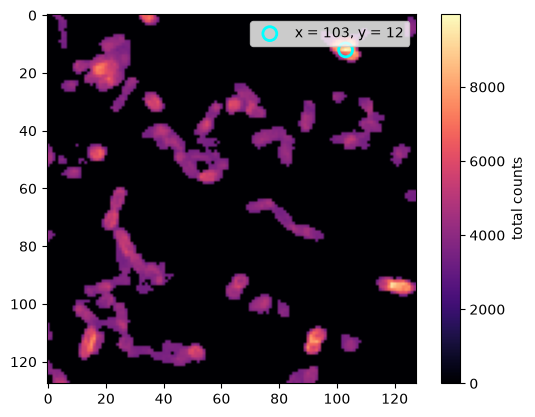

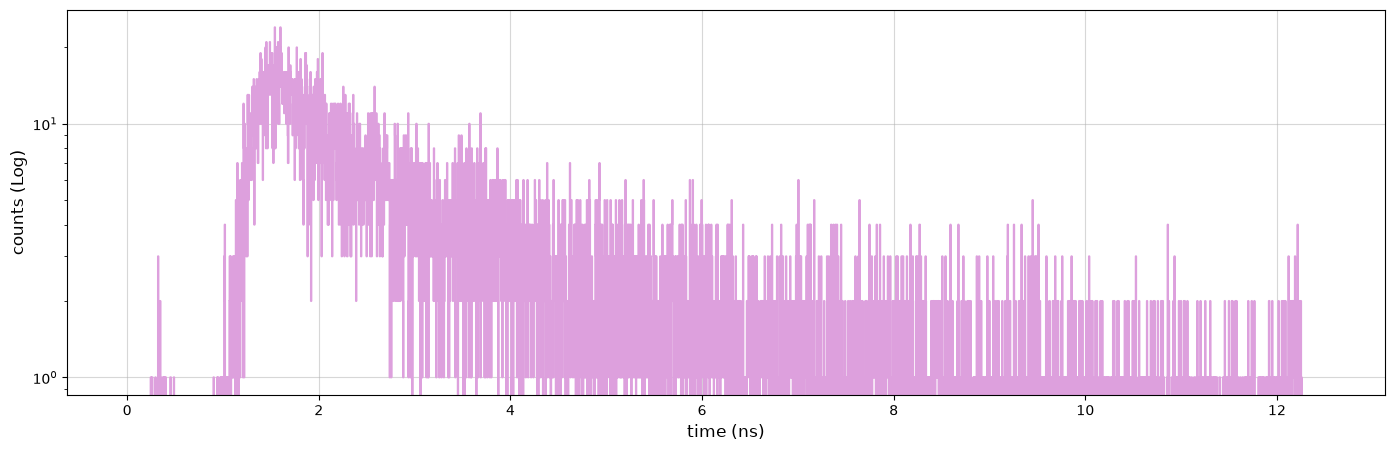

In [ ]:
# function test

image = tiff.imread('./data/FLIM_4_flim_Ch1.tif')   # file name and path
image_flattener(image)
pixel_exponential(image)